In [28]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
%matplotlib inline



In [10]:


df = pd.read_csv("customer_segmentation.csv", encoding="latin1")


In [11]:
df.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [12]:

df = df.dropna(subset=["CustomerID"])


df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]


df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])


In [ ]:

customer_df = df.groupby("CustomerID").agg({
    "Quantity": ["sum", "mean"],
    "UnitPrice": ["sum", "mean"],
    "InvoiceNo": "nunique"
})


customer_df.columns = ["_".join(col).strip() for col in customer_df.columns.values]

customer_df.reset_index(inplace=True)

customer_df.head()


,CustomerID,Quantity_sum,Quantity_mean,UnitPrice_sum,UnitPrice_mean,InvoiceNo_nunique
0,12346.0,74215,74215.000000,1.04,1.040000,1
1,12347.0,2458,13.505495,481.21,2.644011,7
2,12348.0,2341,75.516129,178.71,5.764839,4
3,12349.0,631,8.643836,605.10,8.289041,1
4,12350.0,197,11.588235,65.30,3.841176,1


In [21]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(customer_df.drop("CustomerID", axis=1))


In [22]:

kmeans = KMeans(n_clusters=4, random_state=42)
customer_df["Cluster"] = kmeans.fit_predict(X_scaled)

customer_df.head()


,CustomerID,Quantity_sum,Quantity_mean,UnitPrice_sum,UnitPrice_mean,InvoiceNo_nunique,Cluster
0,12346.0,74215,74215.000000,1.04,1.040000,1,2
1,12347.0,2458,13.505495,481.21,2.644011,7,0
2,12348.0,2341,75.516129,178.71,5.764839,4,0
3,12349.0,631,8.643836,605.10,8.289041,1,0
4,12350.0,197,11.588235,65.30,3.841176,1,0


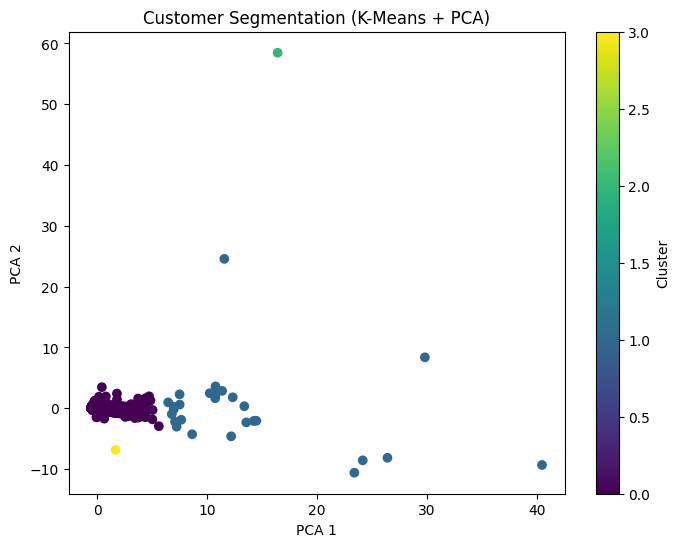

In [30]:
plt.figure(figsize=(8,6))
scatter = plt.scatter(pca_components[:,0], pca_components[:,1], c=customer_df["Cluster"], cmap="viridis")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("Customer Segmentation (K-Means + PCA)")
plt.colorbar(scatter, label="Cluster")
plt.show()


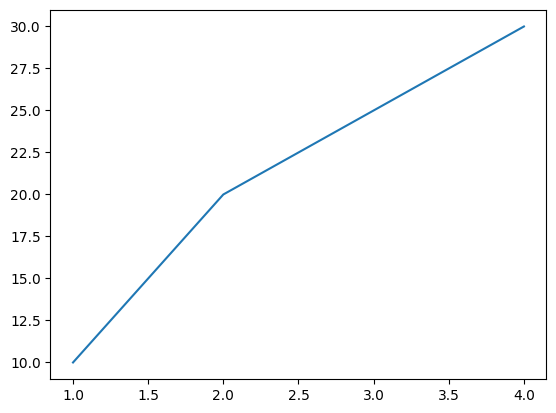

In [29]:
import matplotlib.pyplot as plt
plt.plot([1,2,3,4], [10,20,25,30])
plt.show()
